In [1]:
import pandas as pd
import numpy as np
import librosa
import os, time, inspect, glob, random, itertools
import matplotlib.pyplot as plt

In [2]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import SVC
from sklearn.metrics import f1_score, classification_report, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, LeaveOneGroupOut
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import NearestNeighbors

In [3]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ['PYTHONHASHSEED'] = str(SEED)
path = 'data/schematics-2026'
metas = pd.read_csv(f'{path}/train/metadata.csv')
metas

,file_id,audio_path,label,source_group
0,313fef340a5c0be86a6c3ec29bb0fc5b684accd321f994...,train/audio/313fef340a5c0be86a6c3ec29bb0fc5b68...,Bondol Jawa,d20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7...
1,9f0d58ab5eb8bdad788915ba9053c9a23b2709461ee290...,train/audio/9f0d58ab5eb8bdad788915ba9053c9a23b...,Bondol Jawa,100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c238...
2,f18d5438129a6c8fabe09f8d108c44b0fa40880cf0ffcb...,train/audio/f18d5438129a6c8fabe09f8d108c44b0fa...,Kutilang,81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19...
3,ec4ea61e4451227b2ee1e4046296b515e4f58761ea4097...,train/audio/ec4ea61e4451227b2ee1e4046296b515e4...,Bondol Jawa,d20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7...
4,d0bd6e1839642188508060a7bb5c29c1a8251ada1a48f0...,train/audio/d0bd6e1839642188508060a7bb5c29c1a8...,Kutilang,0d9c30be6d4b5d92c8384b9e5fd3cf908e4b8a965c68a9...
...,...,...,...,...
1821,aa83eca4af347ade7cedd5409c06b8878c062e94b4adc9...,train/audio/aa83eca4af347ade7cedd5409c06b8878c...,Bondol Jawa,d20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7...
1822,7212eee35423e64bdcec85d1418d5d68a6ca11fc45d2fb...,train/audio/7212eee35423e64bdcec85d1418d5d68a6...,Kutilang,81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19...
1823,18a6da4c3e45e6a6cf3f3c51c99b5028902663d537490a...,train/audio/18a6da4c3e45e6a6cf3f3c51c99b502890...,Bondol Jawa,c04cd5b92abf641020d05d3c6493551c25788d00c0cf3d...
1824,bff6da68be0e6f57c7962d267f1854a54b3fba3ab75cbf...,train/audio/bff6da68be0e6f57c7962d267f1854a54b...,Bondol Jawa,90eace95f77b860fc6f9a3ec8c870c251172f7292ca8f6...


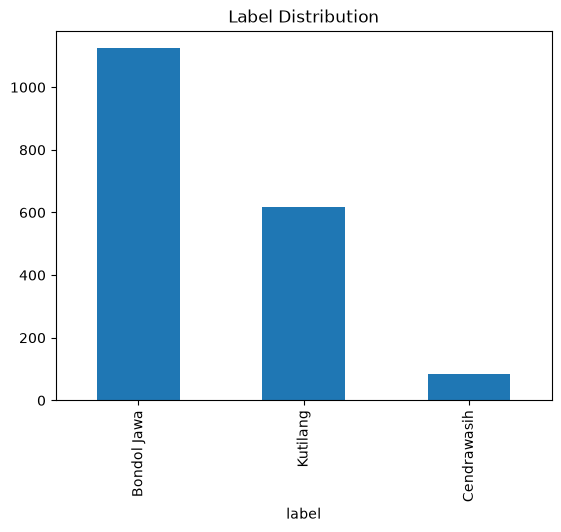

In [4]:
metas['label'].value_counts().plot(kind='bar', title='Label Distribution')
plt.show()

In [5]:
metas.info()

<class 'pandas.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   file_id       1826 non-null   str  
 1   audio_path    1826 non-null   str  
 2   label         1826 non-null   str  
 3   source_group  1826 non-null   str  
dtypes: str(4)
memory usage: 447.7 KB


In [6]:
print(metas.groupby('label')['source_group'].nunique())
metas.groupby(['label', 'source_group']).size()

label
Bondol Jawa    7
Cendrawasih    4
Kutilang       4
Name: source_group, dtype: int64


label        source_group                                                    
Bondol Jawa  100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c2389e1c7964a1e3e19cf9    117
             347254a6f705ce7e515383d02a1c3c81a22ef79a9a2b748e9224327b1a85bbf5     82
             6b857072c74b632b612a73635492716c88e84caf65733651c4b79615b56771c7    232
             90eace95f77b860fc6f9a3ec8c870c251172f7292ca8f6a3748c8d1355549406    123
             c04cd5b92abf641020d05d3c6493551c25788d00c0cf3d20fb547bb5a2218c9b    176
             d20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7b978a1c8096c6a89eb    336
             feb85101266cbc746f76b5403257002d8bd4f5b73d4375a0acd6029e132df6ab     58
Cendrawasih  660c17c0976771310b2cc8ff4db25c3c0638ec870c6a328ea6be82e1b1dbeedb     16
             6895fb85e751062fc362a12424f238cdb6ed5164c09df37e3d0323cff46de107     29
             8a3900e65b5389d260970ab05a5415cbbd4a4548cf0e3f9051f786463c0f7ef3     35
             d7bc3d5bed71ea4c9ab146301ba34f872cb0c68e681ff3cb23328687db1

In [7]:
sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
for k, (tr, va) in enumerate(sgkf.split(metas, metas['label'], groups=metas['source_group'])):
    print(k, metas.iloc[va]['label'].value_counts().to_dict())

0 {'Bondol Jawa': 336, 'Kutilang': 132, 'Cendrawasih': 3}
1 {'Bondol Jawa': 290, 'Kutilang': 143, 'Cendrawasih': 16}
2 {'Bondol Jawa': 240, 'Kutilang': 178, 'Cendrawasih': 35}
3 {'Bondol Jawa': 258, 'Kutilang': 166, 'Cendrawasih': 29}


In [8]:
for d, _, fs in os.walk(path):
    print(d, len(fs), fs[:2])

data/schematics-2026 1 ['sample_submission.csv']
data/schematics-2026\test 0 []
data/schematics-2026\test\audio 814 ['00c2af08a4d5a8c267ee1b2866bbacdd445754fe75c90e05fe2313016808e2ac.flac', '00ca6a7ab9e8ab1e9e580a91cbc4f55bfd9483baa096e75a0a65ba7f3cc3ba37.flac']
data/schematics-2026\train 1 ['metadata.csv']
data/schematics-2026\train\audio 1826 ['002b1299334f4f60b2684134c389988cd855dfe5149810ec3c7b126300b2f396.flac', '0062a08bc8e0b32b9f3e753c2e8d5964f4636b0780b963945c8c857e32416075.flac']


In [9]:
path

'data/schematics-2026'

In [10]:
os.path.exists('data/schematics-2026/train/audio/313fef340a5c0be86a6c3ec29bb0fc5b684accd321f9946e08254c15e20f24e5.flac')

True

In [11]:
for lab, g in metas.groupby('label').head(15).groupby('label'):
    print(lab, len(g))
    print(g['audio_path'])

Bondol Jawa 15
0     train/audio/313fef340a5c0be86a6c3ec29bb0fc5b68...
1     train/audio/9f0d58ab5eb8bdad788915ba9053c9a23b...
3     train/audio/ec4ea61e4451227b2ee1e4046296b515e4...
5     train/audio/cc34621256dd855e6ba019c4341dd28344...
7     train/audio/985bf214018809ddd5a1978285a308f392...
8     train/audio/72ff24682490f553aacdf6dd8f02835584...
9     train/audio/3a13dea9f1eb997c20d9083a8fa64b034d...
10    train/audio/f4cf57bdea9b0493ec095c856c9fefee81...
11    train/audio/a294fc26361ab59c357699bbb58683fd59...
12    train/audio/ab6c4c8d56c202bf9a47d66709f84d0246...
14    train/audio/91fdaeb6e6e84f4386f5ba4e957a2df65b...
15    train/audio/ad3d51694be31d2ae2a224c5b73dff780a...
16    train/audio/b0564bfd0c157f4b6807dbe152a19374e7...
18    train/audio/e9fff6d78d63ca5b518eccb44e2bf0bc8f...
19    train/audio/d8167f807c01a30a8930a33952c2693ac9...
Name: audio_path, dtype: str
Cendrawasih 15
6      train/audio/9f2cfe453f7ea1dc77312d0e2c8ba1647d...
64     train/audio/851569338e5b45efe2cdcf400

In [12]:
# # Cell 2: audit train vs test audio (about 1-2 mins): sample rate + min/median/max seconds
# test_files = [os.path.join(d, f) for d, _, fs in os.walk(f'{path}/test')
#               for f in fs if f.lower().endswith(('.flac', '.wav', '.mp3', '.ogg'))]

# def probe(paths):
#     out = []
#     for p in paths:
#         y, sr = librosa.load(p, sr=None, mono=True)   # sr=None keeps the real rate
#         out.append((sr, len(y) / sr))
#     return np.array(out)

# for lab, g in metas.groupby('label').head(15).groupby('label'):
#     a = probe([f'{path}/{p}' for p in g['audio_path']])
#     print(lab, set(a[:, 0]), np.percentile(a[:, 1], [0, 50, 100]).round(1))
# a = probe(test_files[:45])
# print('TEST', len(test_files), set(a[:, 0]), np.percentile(a[:, 1], [0, 50, 100]).round(1))

In [13]:
metas['have'] = metas['audio_path'].map(lambda p: os.path.exists(f'{path}/{p}'))
print(metas['have'].sum(), len(metas))
print(metas[metas['have']].groupby('label').size())

1826 1826
label
Bondol Jawa    1124
Cendrawasih      83
Kutilang        619
dtype: int64


In [14]:
import birdnet
model = birdnet.load("acoustic", "2.4", "tf", library="litert")   # first run downloads weights
print(inspect.signature(model.encode))                            # shows options like overlap, if any

def embed_file(fp):
    """(n_windows, 1024) embeddings for one file; windows with NaN are dropped."""
    res = model.encode(fp)
    e = np.asarray(res.embeddings, dtype=np.float32)
    e = e.reshape(-1, e.shape[-1])          # (inputs, segments, dim) -> (windows, dim)
    return e[~np.isnan(e).any(axis=1)]

fp = next(f'{path}/{x}' for x in metas['audio_path'] if os.path.exists(f'{path}/{x}'))
t = time.time(); e = embed_file(fp)
print(e.shape, round(time.time() - t, 2), 's')                    # expect (2-4, 1024)

(inp: 'Path | str | Iterable[Path | str]', /, *, n_producers: 'int' = 1, n_workers: 'int | None' = None, batch_size: 'int' = 1, prefetch_ratio: 'int' = 1, overlap_duration_s: 'float' = 0, speed: 'float' = 1.0, bandpass_fmin: 'int' = 0, bandpass_fmax: 'int' = 15000, half_precision: 'bool' = False, max_audio_duration_min: 'float | None' = None, show_stats: "None | Literal['minimal', 'progress', 'benchmark']" = None, progress_callback: 'Callable[[AcousticProgressStats], None] | None' = None, device: 'str | list[str]' = 'CPU', on_file_complete: 'Callable[[AcousticFileEncodingResult], None] | None' = None) -> 'AcousticEncodingResultBase'
(3, 1024) 3.77 s


In [15]:
from tqdm import tqdm
CACHE = 'features/cache'
def extract(items, split):                          # items: list of (file_id, full_path)
    d = f'{CACHE}/{split}'; os.makedirs(d, exist_ok=True)
    X, ids, bad, new = [], [], [], 0
    for fid, fp in tqdm(items):
        out = f'{d}/{fid}.npy'
        try:
            if os.path.exists(out):                 # skip: this file was embedded before
                e = np.load(out)
            else:
                e = embed_file(fp); new += 1
                np.save(out + '.tmp.npy', e)        # write to a temp name first, so an interrupt
                os.replace(out + '.tmp.npy', out)   # never leaves a half-written cache file
            X.append(e); ids += [fid] * len(e)
        except Exception as ex:
            bad.append((fid, repr(ex)[:80]))        # failed files are not cached, so they retry next run
    X = np.vstack(X)
    np.savez_compressed(f'features/{split}_emb_{len(items)}.npz', X=X, ids=np.array(ids))
    print(split, X.shape, '| new:', new, '| failed:', len(bad), bad[:3])

In [16]:
for f in glob.glob('features/*_emb*.npz'):
    d = np.load(f); X, ids = d['X'], d['ids']
    split = 'test' if os.path.basename(f).startswith('test') else 'train'
    os.makedirs(f'{CACHE}/{split}', exist_ok=True)
    for fid in np.unique(ids):
        out = f'{CACHE}/{split}/{fid}.npy'
        if not os.path.exists(out):
            np.save(out, X[ids == fid])             # keeps the window order inside each file
    print('seeded from', f)

seeded from features\test_emb.npz
seeded from features\test_emb_814.npz
seeded from features\train_emb_1826.npz


In [17]:
# Cell C: run. Re-run this whenever more train audio has finished downloading.
EXT = ('.flac', '.wav', '.mp3', '.ogg')
train_items = [(r.file_id, f'{path}/{r.audio_path}') for r in metas.itertuples() if os.path.exists(f'{path}/{r.audio_path}')]        # rebuilt, so it sees new downloads
test_items = [(os.path.splitext(f)[0], os.path.join(d, f)) for d, _, fs in os.walk(f'{path}/test') for f in fs if f.lower().endswith(EXT)]
print(len(train_items), len(test_items))
extract(test_items, 'test')
extract(train_items, 'train')

1826 814


100%|██████████| 814/814 [00:13<00:00, 62.42it/s]


test (3148, 1024) | new: 0 | failed: 0 []


100%|██████████| 1826/1826 [00:29<00:00, 61.55it/s] 


train (7027, 1024) | new: 0 | failed: 0 []


In [18]:
def load_cache(split):
    d = f'features/cache/{split}'
    fids = [f[:-4] for f in os.listdir(d) if f.endswith('.npy') and not f.endswith('.tmp.npy')]
    X, I = [], []
    for fid in fids:
        e = np.load(f'{d}/{fid}.npy'); X.append(e); I += [fid] * len(e)
    return np.vstack(X), np.array(I)

def write_submission(pred, out='submission.csv'):
    """pred: pd.Series indexed by file_id, values = label strings. Checks every rule in the Submission section."""
    sample = pd.read_csv(glob.glob(f'{path}/**/sample_submission.csv', recursive=True)[0])
    assert pred.index.is_unique, 'duplicate file_id'
    assert set(pred.index) == set(sample['file_id']), 'file_id mismatch vs sample_submission'
    assert pred.isin(['Bondol Jawa', 'Cendrawasih', 'Kutilang', 'Unknown']).all(), 'bad label'
    sub = pd.DataFrame({'file_id': sample['file_id'], 'label': pred.loc[sample['file_id']].values})
    sub.to_csv(out, index=False)
    print(out, sub.shape, sub['label'].value_counts().to_dict())

In [19]:
# Cell 2: dry run on whatever train clips are embedded so far. Tests the format only; the score will be poor.
meta = metas.set_index('file_id')
Xtr, itr = load_cache('train'); ytr = meta.loc[itr, 'label'].to_numpy()
print(Xtr.shape, pd.Series(ytr).value_counts().to_dict())    # which birds exist so far
clf = make_pipeline(StandardScaler(),
                    LogisticRegression(C=0.5, class_weight='balanced', max_iter=2000, random_state=42)).fit(Xtr, ytr)
Xte, ite = load_cache('test')
P = pd.DataFrame(clf.predict_proba(Xte), columns=clf.classes_).assign(file_id=ite).groupby('file_id').mean()
write_submission(P.idxmax(axis=1))                           # asserts fail loudly if the format is wrong

(7027, 1024) {'Bondol Jawa': 4281, 'Kutilang': 2420, 'Cendrawasih': 326}
submission.csv (814, 2) {'Bondol Jawa': 374, 'Kutilang': 267, 'Cendrawasih': 173}


In [20]:
meta = metas.set_index('file_id')
X, ids = load_cache('train')                                   # reads the per-file cache from Cell 1
y = meta.loc[ids, 'label'].to_numpy(); g = meta.loc[ids, 'source_group'].to_numpy()
classes = np.unique(y)
print('files embedded:', len(set(ids)), '| source groups per class:', pd.Series(g).groupby(y).nunique().to_dict())

def cv_score(C, cw):
    sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
    oof = np.zeros((len(y), len(classes))); folds = []
    for tr, va in sgkf.split(X, y, groups=g):
        clf = make_pipeline(StandardScaler(),
                            LogisticRegression(C=C, class_weight=cw, max_iter=2000, random_state=42)).fit(X[tr], y[tr])
        assert len(clf.classes_) == len(classes), 'a train fold lost a class'
        oof[va] = clf.predict_proba(X[va])                     # predicted by a model that never saw these groups
        fp = pd.DataFrame(oof[va], columns=classes).assign(file_id=ids[va]).groupby('file_id').mean()
        folds.append(f1_score(meta.loc[fp.index, 'label'], fp.idxmax(axis=1), average='macro', zero_division=0))
    fp = pd.DataFrame(oof, columns=classes).assign(file_id=ids).groupby('file_id').mean()
    pooled = f1_score(meta.loc[fp.index, 'label'], fp.idxmax(axis=1), average='macro', zero_division=0)
    return round(pooled, 3), np.round(folds, 2)

for C, cw in itertools.product([0.01, 0.1, 0.5, 2], ['balanced', None]):   # 8 combos, chosen by hand
    print(C, cw, *cv_score(C, cw))    

files embedded: 1826 | source groups per class: {'Bondol Jawa': 7, 'Cendrawasih': 4, 'Kutilang': 4}
0.01 balanced 0.873 [0.66 0.69 0.9  0.88]
0.01 None 0.883 [0.66 0.65 0.91 0.92]
0.1 balanced 0.865 [0.67 0.69 0.89 0.87]
0.1 None 0.87 [0.66 0.65 0.9  0.89]
0.5 balanced 0.867 [0.67 0.69 0.91 0.86]
0.5 None 0.859 [0.66 0.69 0.88 0.87]
2 balanced 0.86 [0.67 0.69 0.93 0.83]
2 None 0.862 [0.67 0.69 0.93 0.83]


In [21]:
# Cell 1: helpers, then a simulation: hide one bird, treat it as "Unknown", see which signal catches it.
def scores(Xtr, ytr, Xva, C=0.01, k=5):
    """Familiarity of each val window given a train set. Higher = more familiar."""
    sc = StandardScaler().fit(Xtr); A, B = sc.transform(Xtr), sc.transform(Xva)
    lr = LogisticRegression(C=C, class_weight='balanced', max_iter=2000, random_state=42).fit(A, ytr)
    conf = lr.predict_proba(B).max(axis=1)                            # signal 1: how sure the classifier is
    dist = NearestNeighbors(n_neighbors=k, metric='cosine').fit(A).kneighbors(B)[0].mean(axis=1)
    return conf, -dist                                                # signal 2: distance to k closest train windows (negated)

def to_file(s, ids): return pd.Series(np.asarray(s)).groupby(np.asarray(ids)).mean()   # mean score per file

rows = []
for held in classes:
    kn = y != held                                                    # known birds = the other two
    Xk, yk, gk, ik = X[kn], y[kn], g[kn], ids[kn]
    kc, kd = np.zeros(len(yk)), np.zeros(len(yk))
    for tr, va in StratifiedGroupKFold(4, shuffle=True, random_state=42).split(Xk, yk, groups=gk):
        kc[va], kd[va] = scores(Xk[tr], yk[tr], Xk[va])               # known files: scored by models that never saw their groups
    uc, ud = scores(Xk, yk, X[~kn])                                   # held-out bird plays Unknown
    for name, ks, us in [('max-prob', kc, uc), ('knn-dist', kd, ud)]:
        K, U = to_file(ks, ik), to_file(us, ids[~kn])
        auc = roc_auc_score([1] * len(K) + [0] * len(U), np.r_[K.values, U.values])
        caught = (U < np.quantile(K, 0.10)).mean()                    # Unknown caught if we accept losing 10% of known files
        rows.append((held, name, round(auc, 3), round(caught, 2)))
print(pd.DataFrame(rows, columns=['held out (plays Unknown)', 'signal', 'AUROC', 'caught @ 10% known lost']))

  held out (plays Unknown)    signal  AUROC  caught @ 10% known lost
0              Bondol Jawa  max-prob  0.937                     0.80
1              Bondol Jawa  knn-dist  0.659                     0.40
2              Cendrawasih  max-prob  0.849                     0.48
3              Cendrawasih  knn-dist  0.734                     0.52
4                 Kutilang  max-prob  0.834                     0.43
5                 Kutilang  knn-dist  0.869                     0.64


In [22]:
# Cell 2: what each signal says about the real test set (no labels used; automated, so it is rule-safe)
kc, kd = np.zeros(len(y)), np.zeros(len(y))
for tr, va in StratifiedGroupKFold(4, shuffle=True, random_state=42).split(X, y, groups=g):
    kc[va], kd[va] = scores(X[tr], y[tr], X[va])
Xte, ite = load_cache('test')
tc, td = scores(X, y, Xte)
for name, ks, ts in [('max-prob', kc, tc), ('knn-dist', kd, td)]:
    K, T = to_file(ks, ids), to_file(ts, ite)
    for q in [0.05, 0.10, 0.20]:
        print(name, f'known lost {q:.0%} -> test rejected', round((T < np.quantile(K, q)).mean(), 2))

max-prob known lost 5% -> test rejected 0.13
max-prob known lost 10% -> test rejected 0.31
max-prob known lost 20% -> test rejected 0.54
knn-dist known lost 5% -> test rejected 0.36
knn-dist known lost 10% -> test rejected 0.47
knn-dist known lost 20% -> test rejected 0.62


In [23]:
# Cell A: the model, and the familiarity threshold from grouped CV (known birds only)
def fit_lr(Xtr, ytr):
    sc = StandardScaler().fit(Xtr)
    lr = LogisticRegression(C=0.01, class_weight='balanced', max_iter=2000, random_state=SEED).fit(sc.transform(Xtr), ytr)
    return lambda Z: lr.predict_proba(sc.transform(Z))     # window probabilities, columns in sorted class order

kc = np.zeros(len(y))
for tr, va in StratifiedGroupKFold(4, shuffle=True, random_state=SEED).split(X, y, groups=g):
    kc[va] = fit_lr(X[tr], y[tr])(X[va]).max(axis=1)        # top probability per window, from models that never saw these groups
K = to_file(kc, ids)                                        # a known file's familiarity = mean top probability over its windows

In [24]:
# Cell B: fit on all train, predict test, call low-familiarity files Unknown, write one CSV per Q
predict = fit_lr(X, y)
prob = predict(Xte)
P = pd.DataFrame(prob, columns=classes).assign(file_id=ite).groupby('file_id').mean()   # file-level class probabilities
fam = to_file(prob.max(axis=1), ite).loc[P.index]           # file-level familiarity, same recipe as K

for Q in [0.10, 0.20, 0.30]:                                # Q = share of known files we accept rejecting wrongly
    pred = P.idxmax(axis=1)
    pred.loc[(fam < np.quantile(K, Q)).to_numpy()] = 'Unknown'
    print('Q', Q, 'threshold', round(np.quantile(K, Q), 3))
    write_submission(pred, f'submission_q{int(Q * 100)}.csv')

Q 0.1 threshold 0.78
submission_q10.csv (814, 2) {'Bondol Jawa': 264, 'Unknown': 252, 'Kutilang': 185, 'Cendrawasih': 113}
Q 0.2 threshold 0.863
submission_q20.csv (814, 2) {'Unknown': 437, 'Bondol Jawa': 174, 'Kutilang': 148, 'Cendrawasih': 55}
Q 0.3 threshold 0.904
submission_q30.csv (814, 2) {'Unknown': 519, 'Bondol Jawa': 135, 'Kutilang': 115, 'Cendrawasih': 45}


In [26]:
# Cell 1: file-level table (1 row per file = mean of its windows), then a small SVC grid with logistic regression as a control

Xf = pd.DataFrame(X).groupby(ids).mean()
fid, Xf = Xf.index.to_numpy(), Xf.to_numpy()
yf = meta.loc[fid, 'label'].to_numpy(); gf = meta.loc[fid, 'source_group'].to_numpy()
print(Xf.shape, pd.Series(yf).value_counts().to_dict())          # expect 1826 files

def make_model(kind, C, gamma=None):
    if kind == 'svc':
       clf = CalibratedClassifierCV(SVC(kernel='rbf', C=C, gamma=gamma, class_weight='balanced'), method='sigmoid', cv=3)
    else:
        clf = LogisticRegression(C=C, class_weight='balanced', max_iter=2000, random_state=SEED)
    return make_pipeline(StandardScaler(), clf)

def cv_file(kind, C, gamma=None):
    oof = np.zeros((len(yf), len(classes)))
    for tr, va in StratifiedGroupKFold(4, shuffle=True, random_state=SEED).split(Xf, yf, groups=gf):
        oof[va] = make_model(kind, C, gamma).fit(Xf[tr], yf[tr]).predict_proba(Xf[va])   # each file predicted by a model that never saw its group
    return f1_score(yf, classes[oof.argmax(axis=1)], average='macro'), oof

grid = [('lr', 0.01, None), ('lr', 0.1, None)] + [('svc', C, gm) for C in [1, 4] for gm in [0.0003, 0.001, 0.003]]
oofs, res = {}, []
for cfg in grid:
    s, oofs[cfg] = cv_file(*cfg); res.append((cfg, round(s, 3))); print(cfg, round(s, 3))

best_svc = max([r for r in res if r[0][0] == 'svc'], key=lambda r: r[1])[0]
best_lr = max([r for r in res if r[0][0] == 'lr'], key=lambda r: r[1])[0]
for cfg in [best_lr, best_svc]:                                   # per-bird scores, which we haven't looked at yet
    print(cfg); print(classification_report(yf, classes[oofs[cfg].argmax(axis=1)], digits=3))

(1826, 1024) {'Bondol Jawa': 1124, 'Kutilang': 619, 'Cendrawasih': 83}
('lr', 0.01, None) 0.849
('lr', 0.1, None) 0.852
('svc', 1, 0.0003) 0.868
('svc', 1, 0.001) 0.885
('svc', 1, 0.003) 0.723
('svc', 4, 0.0003) 0.878
('svc', 4, 0.001) 0.874
('svc', 4, 0.003) 0.714
('lr', 0.1, None)
              precision    recall  f1-score   support

 Bondol Jawa      0.985     0.931     0.957      1124
 Cendrawasih      0.482     0.807     0.604        83
    Kutilang      0.992     1.000     0.996       619

    accuracy                          0.949      1826
   macro avg      0.820     0.913     0.852      1826
weighted avg      0.964     0.949     0.954      1826

('svc', 1, 0.001)
              precision    recall  f1-score   support

 Bondol Jawa      0.969     0.989     0.979      1124
 Cendrawasih      0.814     0.578     0.676        83
    Kutilang      0.998     1.000     0.999       619

    accuracy                          0.974      1826
   macro avg      0.927     0.856     0.885  

In [27]:
# Cell 2: fake-Unknown test (hide one bird) for the control and the best SVC
def sim_unknown(kind, C, gamma=None):
    rows = []
    for held in classes:
        kn = yf != held                                           # the hidden bird plays Unknown
        Xk, yk, gk = Xf[kn], yf[kn], gf[kn]
        known = np.zeros(len(yk))
        for tr, va in StratifiedGroupKFold(4, shuffle=True, random_state=SEED).split(Xk, yk, groups=gk):
            known[va] = make_model(kind, C, gamma).fit(Xk[tr], yk[tr]).predict_proba(Xk[va]).max(axis=1)
        unk = make_model(kind, C, gamma).fit(Xk, yk).predict_proba(Xf[~kn]).max(axis=1)
        auc = roc_auc_score([1] * len(known) + [0] * len(unk), np.r_[known, unk])
        rows.append((held, round(auc, 3), round((unk < np.quantile(known, 0.10)).mean(), 2)))
    return pd.DataFrame(rows, columns=['hidden bird', 'AUROC', 'caught @ 10% known lost'])

for cfg in [best_lr, best_svc]:
    print(cfg); print(sim_unknown(*cfg))

('lr', 0.1, None)
   hidden bird  AUROC  caught @ 10% known lost
0  Bondol Jawa  0.920                     0.78
1  Cendrawasih  0.875                     0.25
2     Kutilang  0.854                     0.39
('svc', 1, 0.001)
   hidden bird  AUROC  caught @ 10% known lost
0  Bondol Jawa  0.965                     0.94
1  Cendrawasih  0.828                     0.12
2     Kutilang  0.865                     0.32


In [28]:
# Cell 3: final SVC at file level -> two files for your 2 free submissions (about 1 min)
cfg = best_svc                                          # ('svc', 1, 0.001)
Xte, ite = load_cache('test')
Xt = pd.DataFrame(Xte).groupby(ite).mean()              # one row per test file = mean of its windows
fit = make_model(*cfg).fit(Xf, yf)                      # trained on all 1826 train files
Pt = pd.DataFrame(fit.predict_proba(Xt.to_numpy()), columns=classes, index=Xt.index)
K = oofs[cfg].max(axis=1)                               # known-file familiarity from the grouped CV
pred = Pt.idxmax(axis=1)
pred.loc[Pt.max(axis=1) < np.quantile(K, 0.20)] = 'Unknown'    # Q=20%, the better of your two earlier probes
write_submission(pred, 'submission_svc_q20.csv')
write_submission(pd.Series('Unknown', index=Xt.index), 'submission_all_unknown.csv')

submission_svc_q20.csv (814, 2) {'Unknown': 312, 'Bondol Jawa': 264, 'Kutilang': 160, 'Cendrawasih': 78}
submission_all_unknown.csv (814, 2) {'Unknown': 814}


In [29]:
# Existing notebook variables:
# Xf: one averaged embedding vector per recording
# yf: species label per recording
# gf: source_group per recording

SEED = 42
classes_file = np.unique(yf)

models = {
    "LR_C001_balanced": lambda: make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=0.01,
            class_weight="balanced",
            max_iter=2000,
            random_state=SEED,
        ),
    ),
    "LR_C01_unweighted": lambda: make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=0.1,
            class_weight=None,
            max_iter=2000,
            random_state=SEED,
        ),
    ),
    "SVC_RBF_C1_g001": lambda: make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=1,
            gamma=0.001,
            class_weight="balanced",
        ),
    ),
}

# Each specification creates a fresh, deterministic splitter.
splitters = {
    "LOGO": lambda: LeaveOneGroupOut(),
    "SGKF_seed42": lambda: StratifiedGroupKFold(
        n_splits=4, shuffle=True, random_state=42
    ),
    "SGKF_seed7": lambda: StratifiedGroupKFold(
        n_splits=4, shuffle=True, random_state=7
    ),
    "SGKF_seed2026": lambda: StratifiedGroupKFold(
        n_splits=4, shuffle=True, random_state=2026
    ),
}

results = []
logo_predictions = {}

for model_name, build in models.items():
    for split_name, make_splitter in splitters.items():
        splitter = make_splitter()
        oof_pred = np.empty(len(yf), dtype=object)

        for train_idx, val_idx in splitter.split(
            Xf, yf, groups=gf
        ):
            model = build()
            model.fit(Xf[train_idx], yf[train_idx])
            oof_pred[val_idx] = model.predict(Xf[val_idx])

        score = f1_score(
            yf,
            oof_pred,
            labels=classes_file,
            average="macro",
            zero_division=0,
        )

        results.append({
            "model": model_name,
            "validation": split_name,
            "macro_f1_3_known_classes": score,
        })

        if split_name == "LOGO":
            logo_predictions[model_name] = oof_pred.copy()

summary = pd.DataFrame(results)

display(
    summary.pivot(
        index="model",
        columns="validation",
        values="macro_f1_3_known_classes",
    ).round(4)
)

for model_name, predictions in logo_predictions.items():
    print(f"\n{'=' * 55}\n{model_name}\n")
    print(classification_report(
        yf,
        predictions,
        labels=classes_file,
        zero_division=0,
        digits=3,
    ))

# Diagnose source sensitivity using the LOGO predictions.
for model_name, predictions in logo_predictions.items():
    diagnostic = pd.DataFrame({
        "source_group": gf,
        "true_label": yf,
        "correct": predictions == yf,
    })

    print(f"\nPer-source accuracy: {model_name}")
    display(
        diagnostic.groupby(
            ["source_group", "true_label"]
        ).agg(
            recordings=("correct", "size"),
            accuracy=("correct", "mean"),
        ).round(3)
    )


validation,LOGO,SGKF_seed2026,SGKF_seed42,SGKF_seed7
model,,,,
LR_C001_balanced,0.8435,0.8495,0.8495,0.8495
LR_C01_unweighted,0.8781,0.8738,0.8738,0.8738
SVC_RBF_C1_g001,0.8748,0.8916,0.8916,0.8916



LR_C001_balanced

              precision    recall  f1-score   support

 Bondol Jawa      0.987     0.920     0.952      1124
 Cendrawasih      0.448     0.831     0.582        83
    Kutilang      0.992     1.000     0.996       619

    accuracy                          0.943      1826
   macro avg      0.809     0.917     0.843      1826
weighted avg      0.964     0.943     0.950      1826


LR_C01_unweighted

              precision    recall  f1-score   support

 Bondol Jawa      0.977     0.970     0.973      1124
 Cendrawasih      0.640     0.687     0.663        83
    Kutilang      0.997     1.000     0.998       619

    accuracy                          0.967      1826
   macro avg      0.871     0.885     0.878      1826
weighted avg      0.968     0.967     0.968      1826


SVC_RBF_C1_g001

              precision    recall  f1-score   support

 Bondol Jawa      0.969     0.986     0.977      1124
 Cendrawasih      0.758     0.566     0.648        83
    Kutilang      

,,recordings,accuracy
source_group,true_label,,
0d9c30be6d4b5d92c8384b9e5fd3cf908e4b8a965c68a9e5a99d56c81c8bb09b,Kutilang,132,1.000
100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c2389e1c7964a1e3e19cf9,Bondol Jawa,117,0.641
347254a6f705ce7e515383d02a1c3c81a22ef79a9a2b748e9224327b1a85bbf5,Bondol Jawa,82,0.707
660c17c0976771310b2cc8ff4db25c3c0638ec870c6a328ea6be82e1b1dbeedb,Cendrawasih,16,0.312
6895fb85e751062fc362a12424f238cdb6ed5164c09df37e3d0323cff46de107,Cendrawasih,29,1.000
6b857072c74b632b612a73635492716c88e84caf65733651c4b79615b56771c7,Bondol Jawa,232,1.000
81213a446c8b0bbeb4746c7ef40a25f2c28db396267d00bb37901ec3b1ceba6a,Kutilang,166,1.000
81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19a85b167f462b833bae,Kutilang,143,1.000
8a3900e65b5389d260970ab05a5415cbbd4a4548cf0e3f9051f786463c0f7ef3,Cendrawasih,35,0.943



Per-source accuracy: LR_C01_unweighted


,,recordings,accuracy
source_group,true_label,,
0d9c30be6d4b5d92c8384b9e5fd3cf908e4b8a965c68a9e5a99d56c81c8bb09b,Kutilang,132,1.000
100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c2389e1c7964a1e3e19cf9,Bondol Jawa,117,0.855
347254a6f705ce7e515383d02a1c3c81a22ef79a9a2b748e9224327b1a85bbf5,Bondol Jawa,82,0.878
660c17c0976771310b2cc8ff4db25c3c0638ec870c6a328ea6be82e1b1dbeedb,Cendrawasih,16,0.062
6895fb85e751062fc362a12424f238cdb6ed5164c09df37e3d0323cff46de107,Cendrawasih,29,0.966
6b857072c74b632b612a73635492716c88e84caf65733651c4b79615b56771c7,Bondol Jawa,232,1.000
81213a446c8b0bbeb4746c7ef40a25f2c28db396267d00bb37901ec3b1ceba6a,Kutilang,166,1.000
81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19a85b167f462b833bae,Kutilang,143,1.000
8a3900e65b5389d260970ab05a5415cbbd4a4548cf0e3f9051f786463c0f7ef3,Cendrawasih,35,0.800



Per-source accuracy: SVC_RBF_C1_g001


,,recordings,accuracy
source_group,true_label,,
0d9c30be6d4b5d92c8384b9e5fd3cf908e4b8a965c68a9e5a99d56c81c8bb09b,Kutilang,132,1.000
100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c2389e1c7964a1e3e19cf9,Bondol Jawa,117,0.966
347254a6f705ce7e515383d02a1c3c81a22ef79a9a2b748e9224327b1a85bbf5,Bondol Jawa,82,0.939
660c17c0976771310b2cc8ff4db25c3c0638ec870c6a328ea6be82e1b1dbeedb,Cendrawasih,16,0.062
6895fb85e751062fc362a12424f238cdb6ed5164c09df37e3d0323cff46de107,Cendrawasih,29,0.828
6b857072c74b632b612a73635492716c88e84caf65733651c4b79615b56771c7,Bondol Jawa,232,1.000
81213a446c8b0bbeb4746c7ef40a25f2c28db396267d00bb37901ec3b1ceba6a,Kutilang,166,1.000
81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19a85b167f462b833bae,Kutilang,143,1.000
8a3900e65b5389d260970ab05a5415cbbd4a4548cf0e3f9051f786463c0f7ef3,Cendrawasih,35,0.600


In [30]:
# Existing notebook variables:
# Xf: one averaged embedding vector per recording
# yf: species label per recording
# gf: source_group per recording

SEED = 42
classes_file = np.unique(yf)

models = {
    "LR_C001_balanced": lambda: make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=0.01,
            class_weight="balanced",
            max_iter=2000,
            random_state=SEED,
        ),
    ),
    "LR_C01_unweighted": lambda: make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=0.1,
            class_weight=None,
            max_iter=2000,
            random_state=SEED,
        ),
    ),
    "SVC_RBF_C1_g001": lambda: make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=1,
            gamma=0.001,
            class_weight="balanced",
        ),
    ),
}

# Each specification creates a fresh, deterministic splitter.
splitters = {
    "LOGO": lambda: LeaveOneGroupOut(),
    "SGKF_seed42": lambda: StratifiedGroupKFold(
        n_splits=4, shuffle=True, random_state=42
    ),
    "SGKF_seed7": lambda: StratifiedGroupKFold(
        n_splits=4, shuffle=True, random_state=7
    ),
    "SGKF_seed2026": lambda: StratifiedGroupKFold(
        n_splits=4, shuffle=True, random_state=2026
    ),
}

results = []
logo_predictions = {}

for model_name, build in models.items():
    for split_name, make_splitter in splitters.items():
        splitter = make_splitter()
        oof_pred = np.empty(len(yf), dtype=object)

        for train_idx, val_idx in splitter.split(
            Xf, yf, groups=gf
        ):
            model = build()
            model.fit(Xf[train_idx], yf[train_idx])
            oof_pred[val_idx] = model.predict(Xf[val_idx])

        score = f1_score(
            yf,
            oof_pred,
            labels=classes_file,
            average="macro",
            zero_division=0,
        )

        results.append({
            "model": model_name,
            "validation": split_name,
            "macro_f1_3_known_classes": score,
        })

        if split_name == "LOGO":
            logo_predictions[model_name] = oof_pred.copy()

summary = pd.DataFrame(results)

display(
    summary.pivot(
        index="model",
        columns="validation",
        values="macro_f1_3_known_classes",
    ).round(4)
)

for model_name, predictions in logo_predictions.items():
    print(f"\n{'=' * 55}\n{model_name}\n")
    print(classification_report(
        yf,
        predictions,
        labels=classes_file,
        zero_division=0,
        digits=3,
    ))

# Diagnose source sensitivity using the LOGO predictions.
for model_name, predictions in logo_predictions.items():
    diagnostic = pd.DataFrame({
        "source_group": gf,
        "true_label": yf,
        "correct": predictions == yf,
    })

    print(f"\nPer-source accuracy: {model_name}")
    display(
        diagnostic.groupby(
            ["source_group", "true_label"]
        ).agg(
            recordings=("correct", "size"),
            accuracy=("correct", "mean"),
        ).round(3)
    )


validation,LOGO,SGKF_seed2026,SGKF_seed42,SGKF_seed7
model,,,,
LR_C001_balanced,0.8435,0.8495,0.8495,0.8495
LR_C01_unweighted,0.8781,0.8738,0.8738,0.8738
SVC_RBF_C1_g001,0.8748,0.8916,0.8916,0.8916



LR_C001_balanced

              precision    recall  f1-score   support

 Bondol Jawa      0.987     0.920     0.952      1124
 Cendrawasih      0.448     0.831     0.582        83
    Kutilang      0.992     1.000     0.996       619

    accuracy                          0.943      1826
   macro avg      0.809     0.917     0.843      1826
weighted avg      0.964     0.943     0.950      1826


LR_C01_unweighted

              precision    recall  f1-score   support

 Bondol Jawa      0.977     0.970     0.973      1124
 Cendrawasih      0.640     0.687     0.663        83
    Kutilang      0.997     1.000     0.998       619

    accuracy                          0.967      1826
   macro avg      0.871     0.885     0.878      1826
weighted avg      0.968     0.967     0.968      1826


SVC_RBF_C1_g001

              precision    recall  f1-score   support

 Bondol Jawa      0.969     0.986     0.977      1124
 Cendrawasih      0.758     0.566     0.648        83
    Kutilang      

,,recordings,accuracy
source_group,true_label,,
0d9c30be6d4b5d92c8384b9e5fd3cf908e4b8a965c68a9e5a99d56c81c8bb09b,Kutilang,132,1.000
100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c2389e1c7964a1e3e19cf9,Bondol Jawa,117,0.641
347254a6f705ce7e515383d02a1c3c81a22ef79a9a2b748e9224327b1a85bbf5,Bondol Jawa,82,0.707
660c17c0976771310b2cc8ff4db25c3c0638ec870c6a328ea6be82e1b1dbeedb,Cendrawasih,16,0.312
6895fb85e751062fc362a12424f238cdb6ed5164c09df37e3d0323cff46de107,Cendrawasih,29,1.000
6b857072c74b632b612a73635492716c88e84caf65733651c4b79615b56771c7,Bondol Jawa,232,1.000
81213a446c8b0bbeb4746c7ef40a25f2c28db396267d00bb37901ec3b1ceba6a,Kutilang,166,1.000
81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19a85b167f462b833bae,Kutilang,143,1.000
8a3900e65b5389d260970ab05a5415cbbd4a4548cf0e3f9051f786463c0f7ef3,Cendrawasih,35,0.943



Per-source accuracy: LR_C01_unweighted


,,recordings,accuracy
source_group,true_label,,
0d9c30be6d4b5d92c8384b9e5fd3cf908e4b8a965c68a9e5a99d56c81c8bb09b,Kutilang,132,1.000
100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c2389e1c7964a1e3e19cf9,Bondol Jawa,117,0.855
347254a6f705ce7e515383d02a1c3c81a22ef79a9a2b748e9224327b1a85bbf5,Bondol Jawa,82,0.878
660c17c0976771310b2cc8ff4db25c3c0638ec870c6a328ea6be82e1b1dbeedb,Cendrawasih,16,0.062
6895fb85e751062fc362a12424f238cdb6ed5164c09df37e3d0323cff46de107,Cendrawasih,29,0.966
6b857072c74b632b612a73635492716c88e84caf65733651c4b79615b56771c7,Bondol Jawa,232,1.000
81213a446c8b0bbeb4746c7ef40a25f2c28db396267d00bb37901ec3b1ceba6a,Kutilang,166,1.000
81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19a85b167f462b833bae,Kutilang,143,1.000
8a3900e65b5389d260970ab05a5415cbbd4a4548cf0e3f9051f786463c0f7ef3,Cendrawasih,35,0.800



Per-source accuracy: SVC_RBF_C1_g001


,,recordings,accuracy
source_group,true_label,,
0d9c30be6d4b5d92c8384b9e5fd3cf908e4b8a965c68a9e5a99d56c81c8bb09b,Kutilang,132,1.000
100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c2389e1c7964a1e3e19cf9,Bondol Jawa,117,0.966
347254a6f705ce7e515383d02a1c3c81a22ef79a9a2b748e9224327b1a85bbf5,Bondol Jawa,82,0.939
660c17c0976771310b2cc8ff4db25c3c0638ec870c6a328ea6be82e1b1dbeedb,Cendrawasih,16,0.062
6895fb85e751062fc362a12424f238cdb6ed5164c09df37e3d0323cff46de107,Cendrawasih,29,0.828
6b857072c74b632b612a73635492716c88e84caf65733651c4b79615b56771c7,Bondol Jawa,232,1.000
81213a446c8b0bbeb4746c7ef40a25f2c28db396267d00bb37901ec3b1ceba6a,Kutilang,166,1.000
81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19a85b167f462b833bae,Kutilang,143,1.000
8a3900e65b5389d260970ab05a5415cbbd4a4548cf0e3f9051f786463c0f7ef3,Cendrawasih,35,0.600


In [31]:
def evaluate_unknown_proxy(
    X_file,
    y_file,
    groups,
    seed=42,
    rejection_quantiles=(0.05, 0.10, 0.20),
):
    """
    Leave one known species out as a proxy for Unknown.

    For each fold, the SAME model scores:
      1. Known validation recordings from held-out source groups.
      2. Recordings from the withheld species.

    This is an open-set proxy experiment, not an estimate
    of the competition's exact four-class macro F1.
    """
    all_labels = np.unique(y_file)
    rows = []

    for held_species in all_labels:
        known_mask = y_file != held_species
        unknown_mask = ~known_mask

        X_known = X_file[known_mask]
        y_known = y_file[known_mask]
        g_known = groups[known_mask]
        X_unknown = X_file[unknown_mask]

        cv = StratifiedGroupKFold(
            n_splits=3,
            shuffle=True,
            random_state=seed,
        )

        for fold, (tr, va) in enumerate(
            cv.split(X_known, y_known, groups=g_known),
            start=1,
        ):
            model = make_pipeline(
                StandardScaler(),
                LogisticRegression(
                    C=0.01,
                    class_weight="balanced",
                    max_iter=2000,
                    random_state=seed,
                ),
            )
            model.fit(X_known[tr], y_known[tr])

            # Both sets are evaluated by this exact fitted model.
            known_prob = model.predict_proba(X_known[va])
            unknown_prob = model.predict_proba(X_unknown)

            known_conf = known_prob.max(axis=1)
            unknown_conf = unknown_prob.max(axis=1)

            known_pred = model.predict(X_known[va])
            unknown_pred = model.predict(X_unknown)

            proxy_labels = list(model.classes_) + ["Unknown"]
            true_labels = np.concatenate([
                y_known[va],
                np.full(len(X_unknown), "Unknown"),
            ])

            for q in rejection_quantiles:
                threshold = np.quantile(known_conf, q)

                pred_known = np.where(
                    known_conf < threshold,
                    "Unknown",
                    known_pred,
                )
                pred_unknown = np.where(
                    unknown_conf < threshold,
                    "Unknown",
                    unknown_pred,
                )

                predictions = np.concatenate([
                    pred_known,
                    pred_unknown,
                ])

                rows.append({
                    "withheld_species": held_species,
                    "fold": fold,
                    "quantile": q,
                    "threshold": threshold,
                    "known_rejection_rate": np.mean(
                        known_conf < threshold
                    ),
                    "unknown_catch_rate": np.mean(
                        unknown_conf < threshold
                    ),
                    "proxy_macro_f1": f1_score(
                        true_labels,
                        predictions,
                        labels=proxy_labels,
                        average="macro",
                        zero_division=0,
                    ),
                })

    return pd.DataFrame(rows)


unknown_results = evaluate_unknown_proxy(Xf, yf, gf)

display(
    unknown_results.groupby(
        ["withheld_species", "quantile"]
    ).agg(
        proxy_macro_f1=("proxy_macro_f1", "mean"),
        unknown_catch_rate=("unknown_catch_rate", "mean"),
        known_rejection_rate=("known_rejection_rate", "mean"),
    ).round(3)
)


proxy_macro_f1  unknown_catch_rate  \
withheld_species quantile                                       
Bondol Jawa      0.05               0.586               0.565   
                 0.10               0.621               0.647   
                 0.20               0.663               0.757   
Cendrawasih      0.05               0.675               0.145   
                 0.10               0.686               0.273   
                 0.20               0.691               0.534   
Kutilang         0.05               0.354               0.180   
                 0.10               0.435               0.377   
                 0.20               0.511               0.584   

                           known_rejection_rate  
withheld_species quantile                        
Bondol Jawa      0.05                     0.051  
                 0.10                     0.101  
                 0.20                     0.201  
Cendrawasih      0.05                     0.050  
                 0.10                     0.100  
                 0.20                     0.200  
Kutilang         0.05                     0.051  
                 0.10                     0.101  
                 0.20                     0.200

In [32]:
unknown_results = evaluate_unknown_proxy(
    Xf,
    yf,
    gf,
    seed=42,
    rejection_quantiles=(0.10, 0.15, 0.20, 0.25, 0.30),
)

summary = (
    unknown_results
    .groupby("quantile")
    .agg(
        proxy_macro_f1_mean=("proxy_macro_f1", "mean"),
        proxy_macro_f1_std=("proxy_macro_f1", "std"),
        unknown_catch_mean=("unknown_catch_rate", "mean"),
        unknown_catch_std=("unknown_catch_rate", "std"),
        known_rejection_mean=("known_rejection_rate", "mean"),
    )
)

display(summary.round(3))

print("Results by withheld species:")
display(
    unknown_results.pivot_table(
        index="withheld_species",
        columns="quantile",
        values="proxy_macro_f1",
        aggfunc="mean",
    ).round(3)
)

,proxy_macro_f1_mean,proxy_macro_f1_std,unknown_catch_mean,unknown_catch_std,known_rejection_mean
quantile,,,,,
0.10,0.581,0.170,0.433,0.373,0.101
0.15,0.604,0.158,0.532,0.384,0.150
0.20,0.622,0.151,0.625,0.354,0.201
0.25,0.645,0.153,0.792,0.291,0.250
0.30,0.643,0.145,0.836,0.273,0.300


Results by withheld species:


quantile,0.10,0.15,0.20,0.25,0.30
withheld_species,,,,,
Bondol Jawa,0.621,0.639,0.663,0.668,0.678
Cendrawasih,0.686,0.686,0.691,0.740,0.709
Kutilang,0.435,0.487,0.511,0.529,0.544


In [33]:
# Cell A (1 min): what did the SVC file do differently from the logistic-regression file?
a = pd.read_csv('submission_q20.csv').set_index('file_id')['label']        # LogReg, window-level, q20 (scored 0.555)
b = pd.read_csv('submission_svc_q20.csv').set_index('file_id')['label']    # SVC, file-level, q20 (scored 0.507)
print(a.value_counts().to_dict()); print(b.value_counts().to_dict())
pd.crosstab(a, b.loc[a.index], rownames=['LogReg q20'], colnames=['SVC q20'])

{'Unknown': 437, 'Bondol Jawa': 174, 'Kutilang': 148, 'Cendrawasih': 55}
{'Unknown': 312, 'Bondol Jawa': 264, 'Kutilang': 160, 'Cendrawasih': 78}


SVC q20,Bondol Jawa,Cendrawasih,Kutilang,Unknown
LogReg q20,,,,
Bondol Jawa,110,0,1,63
Cendrawasih,5,35,0,15
Kutilang,6,0,135,7
Unknown,143,43,24,227


In [34]:
# Sel 1: dua fungsi. Satu menilai tiap file, satu menjalankan simulasi "spesies disembunyikan = Unknown"
lab = meta['label']                                          # label per file (meta dari sel kita sebelumnya)

def lihat_file(model, X, ids):
    """Per file: tebakan kelas (dari peluang rata-rata) dan keyakinan (rata-rata peluang tertinggi tiap jendela)."""
    P = model.predict_proba(X)
    peluang = pd.DataFrame(P, columns=model.classes_).groupby(ids).mean()
    yakin = pd.Series(P.max(axis=1)).groupby(ids).mean().loc[peluang.index]
    return peluang.idxmax(axis=1), yakin

def proxy_unknown(X, y, g, ids, build, share=0.30, qs=(0.10, 0.20, 0.25, 0.30, 0.40), seeds=(0, 1, 2)):
    rows = []
    for held in np.unique(y):                                # spesies yang disembunyikan berperan sebagai Unknown
        kn = y != held
        Xk, yk, gk, ik = X[kn], y[kn], g[kn], ids[kn]
        for seed in seeds:
            rng = np.random.default_rng(seed)
            for tr, va in StratifiedGroupKFold(3, shuffle=True, random_state=seed).split(Xk, yk, groups=gk):
                m = build().fit(Xk[tr], yk[tr])
                pk, fk = lihat_file(m, Xk[va], ik[va])       # file dikenal dari kelompok sumber yang ditahan
                pu, fu = lihat_file(m, X[~kn], ids[~kn])     # file spesies yang disembunyikan
                thr = {q: np.quantile(fk, q) for q in qs}    # ambang: q% file dikenal yang paling ragu
                # samakan porsi Unknown = share (kurangi sisi yang lebih banyak)
                if len(fu) / (len(fu) + len(fk)) > share:
                    keep_k, keep_u = fk.index, rng.choice(fu.index, round(len(fk) * share / (1 - share)), replace=False)
                else:
                    keep_k, keep_u = rng.choice(fk.index, round(len(fu) * (1 - share) / share), replace=False), fu.index
                true = np.r_[lab.loc[keep_k].to_numpy(), ['Unknown'] * len(keep_u)]
                labs = list(m.classes_) + ['Unknown']
                for q in qs:
                    tk, tu = fk.loc[keep_k] < thr[q], fu.loc[keep_u] < thr[q]      # True = ditolak jadi Unknown
                    pred = np.r_[np.where(tk, 'Unknown', pk.loc[keep_k]), np.where(tu, 'Unknown', pu.loc[keep_u])]
                    rows.append(dict(hidden=held, q=q, seed=seed,
                                     share=len(keep_u) / (len(keep_u) + len(keep_k)),
                                     f1=f1_score(true, pred, labels=labs, average='macro', zero_division=0),
                                     f1_unknown=f1_score(true, pred, labels=['Unknown'], average='macro', zero_division=0),
                                     catch=tu.mean(), known_lost=tk.mean()))
    return pd.DataFrame(rows)

In [35]:
# Sel 2, hanya satu angka yang berubah: porsi Unknown 0.38 (tadinya 0.30)
res = proxy_unknown(X, y, g, ids, lambda: make_model('lr', 0.01), share=0.38)
print(res.groupby('hidden')['share'].mean().round(2).to_dict())          # harus sekitar 0.38
print(res.groupby(['hidden', 'q'])[['f1', 'f1_unknown', 'catch', 'known_lost']].mean().round(3).to_string())
print(res.groupby('q').agg(f1=('f1', 'mean'), sd=('f1', 'std'), f1_unknown=('f1_unknown', 'mean'),
                           catch=('catch', 'mean'), known_lost=('known_lost', 'mean')).round(3).to_string())

{'Bondol Jawa': 0.38, 'Cendrawasih': 0.38, 'Kutilang': 0.38}
                     f1  f1_unknown  catch  known_lost
hidden      q                                         
Bondol Jawa 0.10  0.759       0.833  0.838       0.101
            0.20  0.715       0.819  0.923       0.201
            0.25  0.675       0.802  0.944       0.251
            0.30  0.644       0.780  0.953       0.299
            0.40  0.590       0.739  0.970       0.400
Cendrawasih 0.10  0.691       0.450  0.369       0.097
            0.20  0.730       0.600  0.590       0.210
            0.25  0.759       0.680  0.731       0.248
            0.30  0.750       0.693  0.799       0.303
            0.40  0.734       0.724  0.940       0.402
Kutilang    0.10  0.547       0.572  0.473       0.101
            0.20  0.578       0.662  0.663       0.200
            0.25  0.572       0.686  0.740       0.250
            0.30  0.565       0.687  0.783       0.300
            0.40  0.545       0.690  0.874       0.400
    

In [36]:
# File baru: 38% file tes paling tidak yakin jadi Unknown (ambang dari peringkat tes, bukan dari CV)
prob = fit_lr(X, y)(Xte)                                              # LogReg per jendela, C=0.01, balanced
P = pd.DataFrame(prob, columns=classes).assign(file_id=ite).groupby('file_id').mean()
fam = to_file(prob.max(axis=1), ite).loc[P.index]                     # keyakinan per file
pred = P.idxmax(axis=1)
pred.loc[fam < np.quantile(fam, 0.38)] = 'Unknown'
write_submission(pred, 'submission_lr_rank38.csv')

submission_lr_rank38.csv (814, 2) {'Unknown': 309, 'Bondol Jawa': 238, 'Kutilang': 175, 'Cendrawasih': 92}


In [37]:
# Uji kepekaan (perkiraan 5-15 menit): kalau porsi Unknown sebenarnya 0.32 atau 0.44 (bukan 0.38),
# seberapa berubah skor kebijakan "tolak f% file yang paling tidak yakin"?
def proxy_rank(X, y, g, ids, build, share, fs=(0.30, 0.34, 0.38, 0.42, 0.46), seeds=(0, 1)):
    rows = []
    for held in np.unique(y):
        kn = y != held
        Xk, yk, gk, ik = X[kn], y[kn], g[kn], ids[kn]
        for seed in seeds:
            rng = np.random.default_rng(seed)
            for tr, va in StratifiedGroupKFold(3, shuffle=True, random_state=seed).split(Xk, yk, groups=gk):
                m = build().fit(Xk[tr], yk[tr])
                pk, fk = lihat_file(m, Xk[va], ik[va]); pu, fu = lihat_file(m, X[~kn], ids[~kn])
                if len(fu) / (len(fu) + len(fk)) > share:
                    keep_k, keep_u = fk.index, rng.choice(fu.index, round(len(fk) * share / (1 - share)), replace=False)
                else:
                    keep_k, keep_u = rng.choice(fk.index, round(len(fu) * (1 - share) / share), replace=False), fu.index
                pooled = np.r_[fk.loc[keep_k], fu.loc[keep_u]]              # keyakinan semua file yang dinilai
                true = np.r_[lab.loc[keep_k].to_numpy(), ['Unknown'] * len(keep_u)]
                labs = list(m.classes_) + ['Unknown']
                for f in fs:
                    thr = np.quantile(pooled, f)                             # tolak f% file yang paling tidak yakin
                    tk, tu = fk.loc[keep_k] < thr, fu.loc[keep_u] < thr
                    pred = np.r_[np.where(tk, 'Unknown', pk.loc[keep_k]), np.where(tu, 'Unknown', pu.loc[keep_u])]
                    rows.append(dict(f=f, share=share, f1=f1_score(true, pred, labels=labs, average='macro', zero_division=0)))
    return pd.DataFrame(rows)

out = pd.concat([proxy_rank(X, y, g, ids, lambda: make_model('lr', 0.01), s) for s in (0.32, 0.38, 0.44)])
print(out.pivot_table(index='f', columns='share', values='f1', aggfunc='mean').round(3).to_string())

share   0.32   0.38   0.44
f                         
0.30   0.700  0.683  0.658
0.34   0.699  0.696  0.678
0.38   0.694  0.700  0.693
0.42   0.684  0.693  0.696
0.46   0.673  0.685  0.698
